# 2.1 Load and Inspect Dataset

In [ ]:

from pathlib import Path
import pandas as pd


print("Current directory:", Path.cwd())

parquet_files = list(Path.cwd().rglob("*.parquet"))

for file in parquet_files:
    print(file)


Current directory: c:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\notebooks\notebooks


In [ ]:


file_path = r"C:\Users\King\OneDrive\Desktop\Berlin-Mobility-AI\data\processed\berlin_traffic_all_years.parquet"

df = pd.read_parquet(file_path)

print("Dataset loaded successfully!")


print("Shape:", df.shape)

display(df.head(10))


Dataset loaded successfully!
Shape: (3471646, 4)


,timestamp,station_id,bicycle_count,year
0,2023-01-01 00:00:00,01-MI-AL-W,6.0,2023
1,2023-01-01 01:00:00,01-MI-AL-W,17.0,2023
2,2023-01-01 02:00:00,01-MI-AL-W,17.0,2023
3,2023-01-01 03:00:00,01-MI-AL-W,13.0,2023
4,2023-01-01 04:00:00,01-MI-AL-W,12.0,2023
5,2023-01-01 05:00:00,01-MI-AL-W,12.0,2023
6,2023-01-01 06:00:00,01-MI-AL-W,11.0,2023
7,2023-01-01 07:00:00,01-MI-AL-W,7.0,2023
8,2023-01-01 08:00:00,01-MI-AL-W,6.0,2023
9,2023-01-01 09:00:00,01-MI-AL-W,17.0,2023


In [12]:

# Column names
print("COLUMNS:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDATA INFORMATION:")
df.info()

# Missing values per column
print("\nMISSING VALUES:")
print(df.isna().sum())

# Duplicate rows
print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())


COLUMNS:
['timestamp', 'station_id', 'bicycle_count', 'year']

DATA INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 3471646 entries, 0 to 3471645
Data columns (total 4 columns):
 #   Column         Dtype         
---  ------         -----         
 0   timestamp      datetime64[us]
 1   station_id     str           
 2   bicycle_count  float64       
 3   year           int64         
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 140.1 MB

MISSING VALUES:
timestamp             0
station_id            0
bicycle_count    953447
year                  0
dtype: int64

DUPLICATE ROWS:
0


In [13]:

print("Number of stations:", df["station_id"].nunique())

print("First date:", df["timestamp"].min())
print("Last date:", df["timestamp"].max())

print("\nYears available:")
print(sorted(df["year"].unique()))

print("\nObservations per year:")
print(df.groupby("year").size())


Number of stations: 39
First date: 2012-01-01 00:00:00
Last date: 2025-12-31 23:00:00

Years available:
[np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Observations per year:
year
2012    228384
2013    227760
2014    227760
2015    227760
2016    228384
2017    227760
2018    227760
2019    227734
2020    228384
2021    254040
2022    262800
2023    289080
2024    307440
2025    306600
dtype: int64


## 2.2 Data Quality Analysis

In [ ]:

# we will check missing values by year
missing_by_year = (
    df.groupby("year")["bicycle_count"]
    .agg(
        total="size",
        missing=lambda x: x.isna().sum()
    )
)

missing_by_year["missing_pct"] = (
    missing_by_year["missing"] /
    missing_by_year["total"] * 100
)

display(missing_by_year.round(2))

#We want to discover whether missing values are concentrated in earlier years or spread across the entire dataset.

,total,missing,missing_pct
year,,,
2012,228384,221042,96.79
2013,227760,219000,96.15
2014,227760,219000,96.15
2015,227760,144159,63.29
2016,228384,37096,16.24
2017,227760,721,0.32
2018,227760,22,0.01
2019,227734,32,0.01
2020,228384,1969,0.86


In [ ]:

# we will check missing values by station
missing_by_station = (
    df.groupby("station_id")["bicycle_count"]
    .agg(
        total="size",
        missing=lambda x: x.isna().sum()
    )
)

missing_by_station["missing_pct"] = (
    missing_by_station["missing"] /
    missing_by_station["total"] * 100
)

display(
    missing_by_station
    .sort_values("missing_pct", ascending=False)
    .round(2)
)
#This will show which stations have the poorest data coverage.

,total,missing,missing_pct
station_id,,,
02-PA-SE-N,8760,8760,100.00
02-MI-AL-W,17520,17152,97.90
03-SP-NO-W,8760,7812,89.18
03-SP-NO-O,8760,7812,89.18
05-FK-OBB-W,122735,42596,34.71
05-FK-OBB-O,122735,42572,34.69
04-MI-NO,26304,8904,33.85
06-FK-FRA-W,122735,38884,31.68
06-FK-FRA-O,122735,38786,31.60


In [18]:

#Check invalid bicycle counts and timestamp duplicates

print("Negative bicycle counts:",
      (df["bicycle_count"] < 0).sum())

print("Zero bicycle counts:",
      (df["bicycle_count"] == 0).sum())

print("Duplicate station-timestamps:",
      df.duplicated(
          subset=["station_id", "timestamp"]
      ).sum())

print("Year mismatches:",
      (df["year"] != df["timestamp"].dt.year).sum())

print("\nBicycle count statistics:")
display(df["bicycle_count"].describe())


Negative bicycle counts: 0
Zero bicycle counts: 109716
Duplicate station-timestamps: 0
Year mismatches: 0

Bicycle count statistics:


count    2.518199e+06
mean     9.209499e+01
std      1.132495e+02
min      0.000000e+00
25%      1.200000e+01
50%      4.900000e+01
75%      1.320000e+02
max      3.155000e+03
Name: bicycle_count, dtype: float64

In [19]:

# Number of valid bicycle observations per station per year
station_year_coverage = (
    df.assign(
        valid=df["bicycle_count"].notna()
    )
    .groupby(["station_id", "year"])
    .agg(
        total=("valid", "size"),
        valid=("valid", "sum")
    )
)

station_year_coverage["coverage_pct"] = (
    station_year_coverage["valid"] /
    station_year_coverage["total"] * 100
)

coverage_matrix = (
    station_year_coverage["coverage_pct"]
    .unstack("year")
)

display(coverage_matrix.round(1))


year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
station_id,,,,,,,,,,,,,,
01-MI-AL-W,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,99.9,100.0
02-MI-AL-W,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.2,0.0,NaN,NaN,NaN
02-MI-JAN-N,0.0,0.0,0.0,75.3,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
02-MI-JAN-S,0.0,0.0,0.0,75.3,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,95.5,100.0
02-PA-SE-N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
03-MI-SAN-O,0.0,0.0,0.0,58.6,100.0,100.0,100.0,100.0,100.0,100.0,100.0,99.7,100.0,100.0
03-MI-SAN-W,0.0,0.0,0.0,58.6,100.0,100.0,100.0,99.9,100.0,100.0,100.0,100.0,100.0,100.0
03-SP-NO-O,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.8,NaN,NaN
03-SP-NO-W,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.8,NaN,NaN


Matplotlib is building the font cache; this may take a moment.


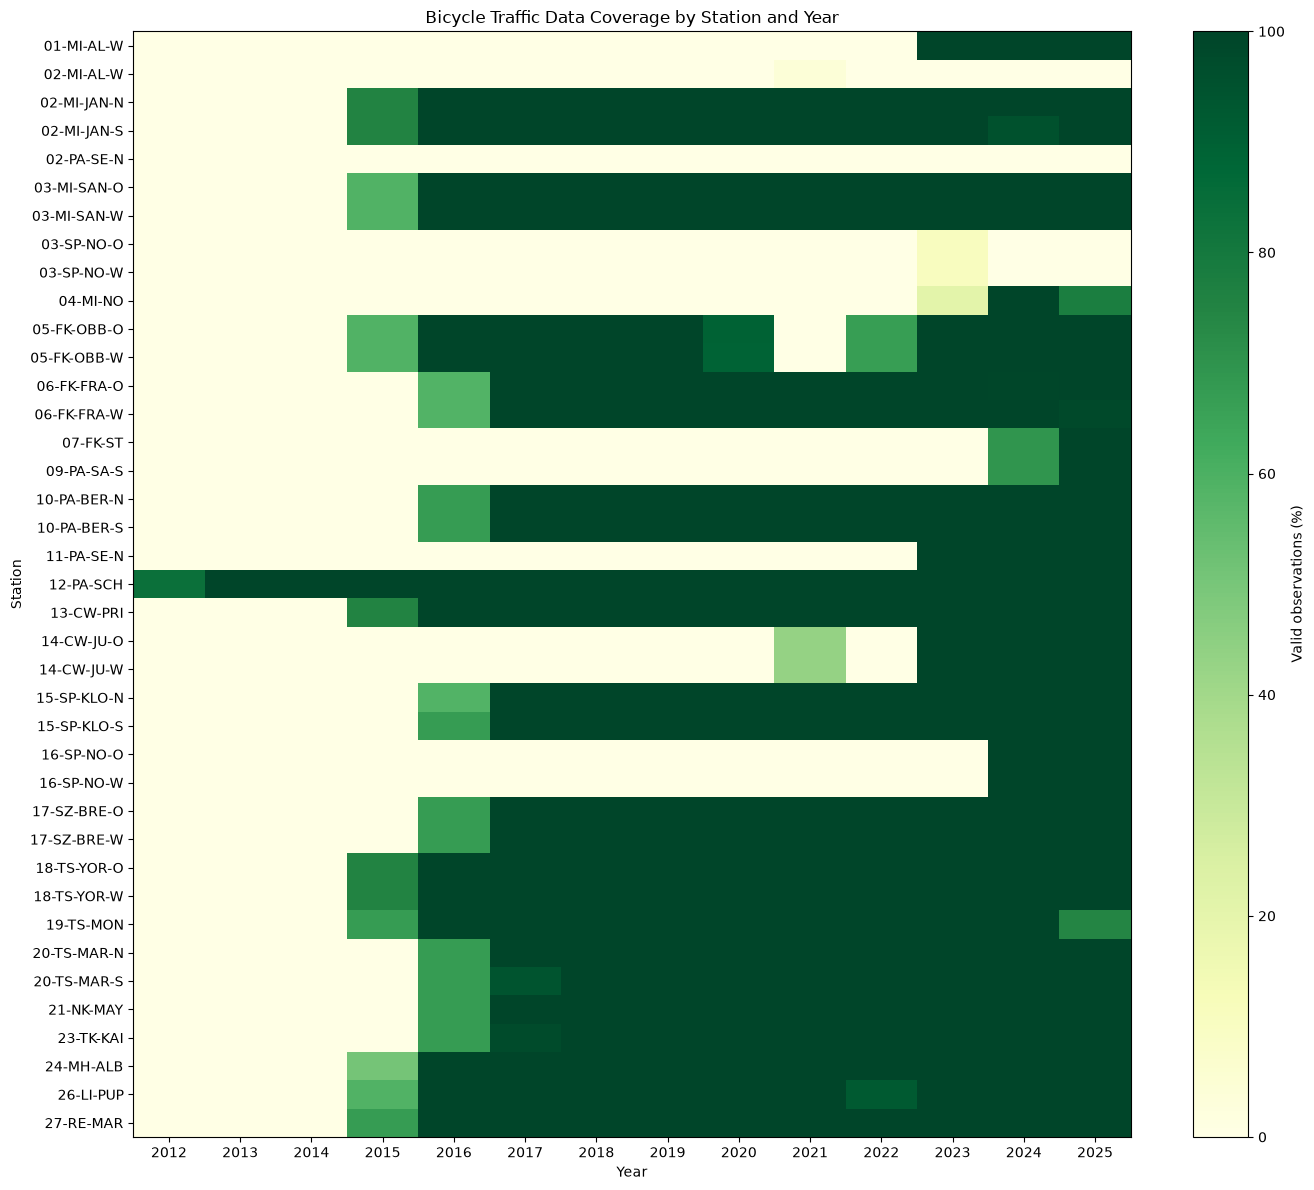

In [20]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 12))

plt.imshow(
    coverage_matrix.fillna(0),
    aspect="auto",
    cmap="YlGn",
    vmin=0,
    vmax=100
)

plt.colorbar(label="Valid observations (%)")

plt.xticks(
    range(len(coverage_matrix.columns)),
    coverage_matrix.columns
)

plt.yticks(
    range(len(coverage_matrix.index)),
    coverage_matrix.index
)

plt.xlabel("Year")
plt.ylabel("Station")
plt.title("Bicycle Traffic Data Coverage by Station and Year")

plt.tight_layout()
plt.show()


In [21]:

counts = df["bicycle_count"].dropna()

print("Negative counts:", (counts < 0).sum())

print("Fractional counts:",
      (counts % 1 != 0).sum())

print("Zero counts:", (counts == 0).sum())

print("\nCount distribution:")
display(
    counts.describe(
        percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
    )
)

print("\nTop 10 highest observations:")
display(
    df.nlargest(10, "bicycle_count")[
        ["timestamp", "station_id", "bicycle_count"]
    ]
)


Negative counts: 0
Fractional counts: 0
Zero counts: 109716

Count distribution:


count    2.518199e+06
mean     9.209499e+01
std      1.132495e+02
min      0.000000e+00
50%      4.900000e+01
90%      2.420000e+02
95%      3.240000e+02
99%      5.110000e+02
99.9%    7.530000e+02
max      3.155000e+03
Name: bicycle_count, dtype: float64


Top 10 highest observations:


,timestamp,station_id,bicycle_count
2847205,2024-10-09 10:00:00,20-TS-MAR-S,3155.0
2847206,2024-10-09 11:00:00,20-TS-MAR-S,2720.0
117733,2020-06-06 14:00:00,02-MI-JAN-N,2167.0
2583887,2022-09-26 18:00:00,19-TS-MON,2023.0
2847207,2024-10-09 12:00:00,20-TS-MAR-S,1876.0
117732,2020-06-06 13:00:00,02-MI-JAN-N,1757.0
2583815,2022-09-23 18:00:00,19-TS-MON,1677.0
240469,2020-06-06 15:00:00,02-MI-JAN-S,1592.0
2583706,2022-09-19 05:00:00,19-TS-MON,1587.0
2584402,2022-10-18 05:00:00,19-TS-MON,1585.0


## 2.3 Data Cleaning

In [22]:

# Step 2.3 — Initial data cleaning

import pandas as pd

# Work on a separate copy
clean_df = df.copy()

# Restrict the analysis period
clean_df = clean_df[
    (clean_df["timestamp"] >= "2017-01-01") &
    (clean_df["timestamp"] < "2026-01-01")
].copy()

# Exclude stations with insufficient overall data
excluded_stations = [
    "02-PA-SE-N",
    "02-MI-AL-W",
    "03-SP-NO-O",
    "03-SP-NO-W"
]

clean_df = clean_df[
    ~clean_df["station_id"].isin(excluded_stations)
].copy()

# Remove missing target observations
clean_df = clean_df.dropna(
    subset=["bicycle_count"]
).copy()

# Sort the data chronologically
clean_df = clean_df.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

print("Original dataset:", df.shape)
print("Cleaned dataset:", clean_df.shape)

print("Stations retained:",
      clean_df["station_id"].nunique())

print("Missing counts:",
      clean_df["bicycle_count"].isna().sum())

print("Date range:",
      clean_df["timestamp"].min(),
      "to",
      clean_df["timestamp"].max())


Original dataset: (3471646, 4)
Cleaned dataset: (2216184, 4)
Stations retained: 35
Missing counts: 0
Date range: 2017-01-01 00:00:00 to 2025-12-31 23:00:00


In [32]:

from pathlib import Path

# Create output folder
output_dir = Path("C:/Users/King/OneDrive/Desktop/Berlin-Mobility-AI/data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
clean_df.to_parquet(
    output_dir / "berlin_bicycle_cleaned.parquet",
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [39]:
# We also need to confirm that we don't have multiple readings for the same station and hour, even when the readings differ.
print(
    "Duplicate station-timestamp pairs:",
    clean_df.duplicated(
        subset=["station_id", "timestamp"]
    ).sum()
)

print("\nObservations by year:")
display(clean_df.groupby("year").size())

print("\nBicycle count statistics:")
display(clean_df["bicycle_count"].describe())


Duplicate station-timestamp pairs: 0

Observations by year:


year
2017    227039
2018    227738
2019    227702
2020    226415
2021    217801
2022    221182
2023    264575
2024    301558
2025    302174
dtype: int64


Bicycle count statistics:


count    2.216184e+06
mean     9.092420e+01
std      1.127444e+02
min      0.000000e+00
25%      1.100000e+01
50%      4.800000e+01
75%      1.310000e+02
max      3.155000e+03
Name: bicycle_count, dtype: float64

##  2.4 Exploratory Data Analysis

In [46]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create a separate dataframe for EDA
eda_df = clean_df.copy()

# Extract time information
eda_df["hour"] = eda_df["timestamp"].dt.hour
eda_df["day_of_week"] = eda_df["timestamp"].dt.dayofweek
eda_df["month"] = eda_df["timestamp"].dt.month
eda_df["is_weekend"] = eda_df["day_of_week"] >= 5

print("EDA dataset shape:", eda_df.shape)

display(eda_df.head(25))


EDA dataset shape: (2216184, 8)


,timestamp,station_id,bicycle_count,year,hour,day_of_week,month,is_weekend
0,2023-01-01 00:00:00,01-MI-AL-W,6.0,2023,0,6,1,True
1,2023-01-01 01:00:00,01-MI-AL-W,17.0,2023,1,6,1,True
2,2023-01-01 02:00:00,01-MI-AL-W,17.0,2023,2,6,1,True
3,2023-01-01 03:00:00,01-MI-AL-W,13.0,2023,3,6,1,True
4,2023-01-01 04:00:00,01-MI-AL-W,12.0,2023,4,6,1,True
5,2023-01-01 05:00:00,01-MI-AL-W,12.0,2023,5,6,1,True
6,2023-01-01 06:00:00,01-MI-AL-W,11.0,2023,6,6,1,True
7,2023-01-01 07:00:00,01-MI-AL-W,7.0,2023,7,6,1,True
8,2023-01-01 08:00:00,01-MI-AL-W,6.0,2023,8,6,1,True
9,2023-01-01 09:00:00,01-MI-AL-W,17.0,2023,9,6,1,True


In [47]:

# Select stations with consistent coverage(stations that have at least 95% of the expected hourly measurements in every year from 2017 through 2025.)

years = list(range(2017, 2026))

# Expected hours per year (including leap years)
expected_hours = pd.Series({
    year: int(
        (pd.Timestamp(year + 1, 1, 1) -
         pd.Timestamp(year, 1, 1))
        / pd.Timedelta(hours=1)
    )
    for year in years
})

# Count valid observations at each station per year
station_hours = (
    eda_df.groupby(["station_id", "year"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=years, fill_value=0)
)

# Coverage relative to expected annual hours
coverage = station_hours.div(
    expected_hours, axis="columns"
)

# Stations with >= 95% coverage in EVERY year
stable_stations = coverage.index[
    coverage.ge(0.95).all(axis=1)
]

# Balanced dataset for comparable time trends
eda_stable = eda_df[
    eda_df["station_id"].isin(stable_stations)
].copy()

print("Stable stations:", len(stable_stations))
print("Stable dataset shape:", eda_stable.shape)
print("\nStations selected:")
print(stable_stations.tolist())


Stable stations: 21
Stable dataset shape: (1655558, 8)

Stations selected:
['02-MI-JAN-N', '02-MI-JAN-S', '03-MI-SAN-O', '03-MI-SAN-W', '06-FK-FRA-O', '06-FK-FRA-W', '10-PA-BER-N', '10-PA-BER-S', '12-PA-SCH', '13-CW-PRI', '15-SP-KLO-N', '15-SP-KLO-S', '17-SZ-BRE-O', '17-SZ-BRE-W', '18-TS-YOR-O', '18-TS-YOR-W', '20-TS-MAR-N', '21-NK-MAY', '23-TK-KAI', '24-MH-ALB', '27-RE-MAR']


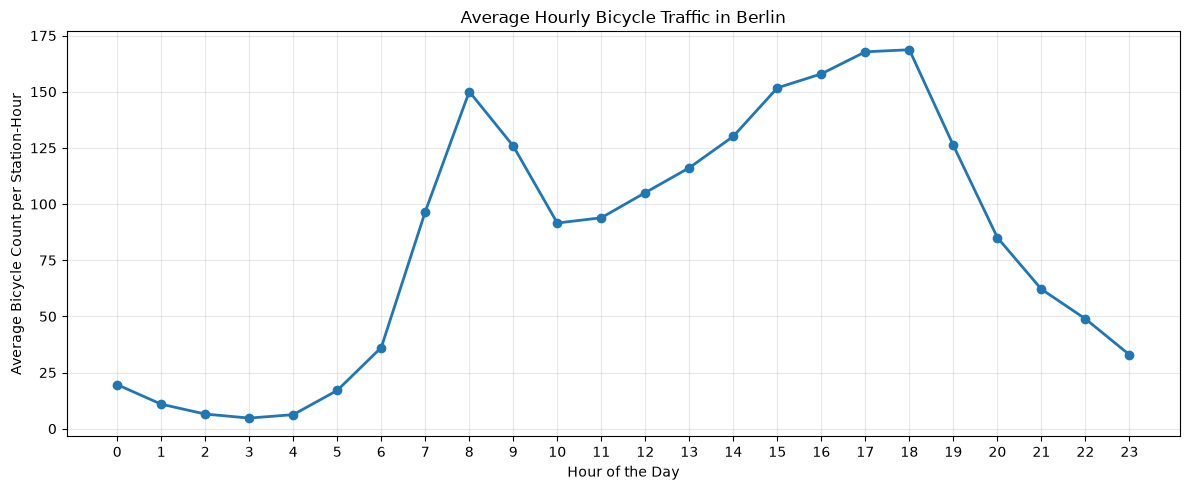

Peak traffic hour: 18
Lowest traffic hour: 3


In [48]:

# Average bicycle count by hour
hourly_traffic = (
    eda_stable.groupby("hour")["bicycle_count"]
    .mean()
    .reindex(range(24))
)

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_traffic.index,
    hourly_traffic.values,
    marker="o",
    linewidth=2
)

plt.title("Average Hourly Bicycle Traffic in Berlin")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Bicycle Count per Station-Hour")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Peak traffic hour:", hourly_traffic.idxmax())
print("Lowest traffic hour:", hourly_traffic.idxmin())


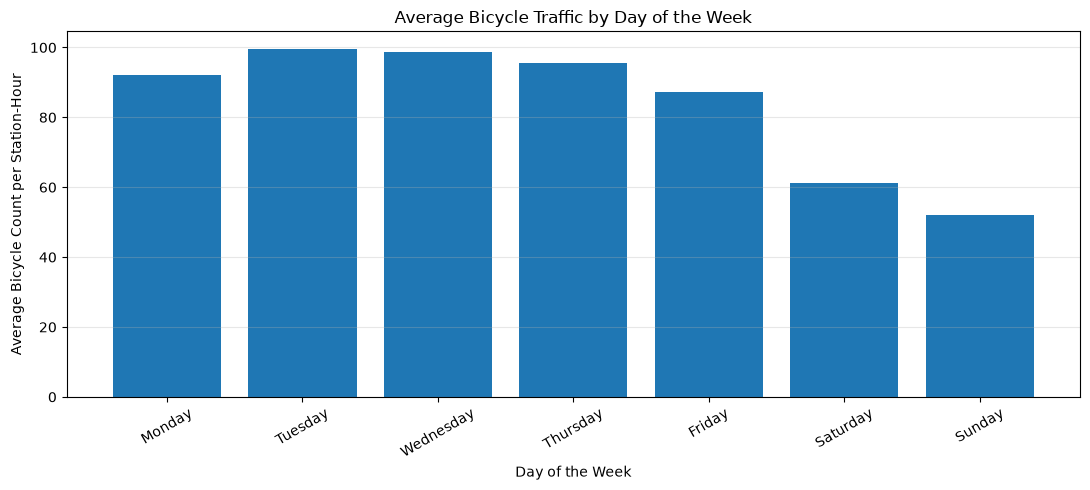

Average traffic by weekday:


,day,average_count
0,Monday,92.26
1,Tuesday,99.64
2,Wednesday,98.65
3,Thursday,95.45
4,Friday,87.35
5,Saturday,61.33
6,Sunday,52.19


In [49]:

# Average count for each day of the week
daily_traffic = (
    eda_stable.groupby("day_of_week")["bicycle_count"]
    .mean()
    .reindex(range(7))
)

day_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(11, 5))

plt.bar(
    day_names,
    daily_traffic.values
)

plt.title("Average Bicycle Traffic by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Bicycle Count per Station-Hour")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Average traffic by weekday:")
display(
    pd.DataFrame({
        "day": day_names,
        "average_count": daily_traffic.values
    }).round(2)
)


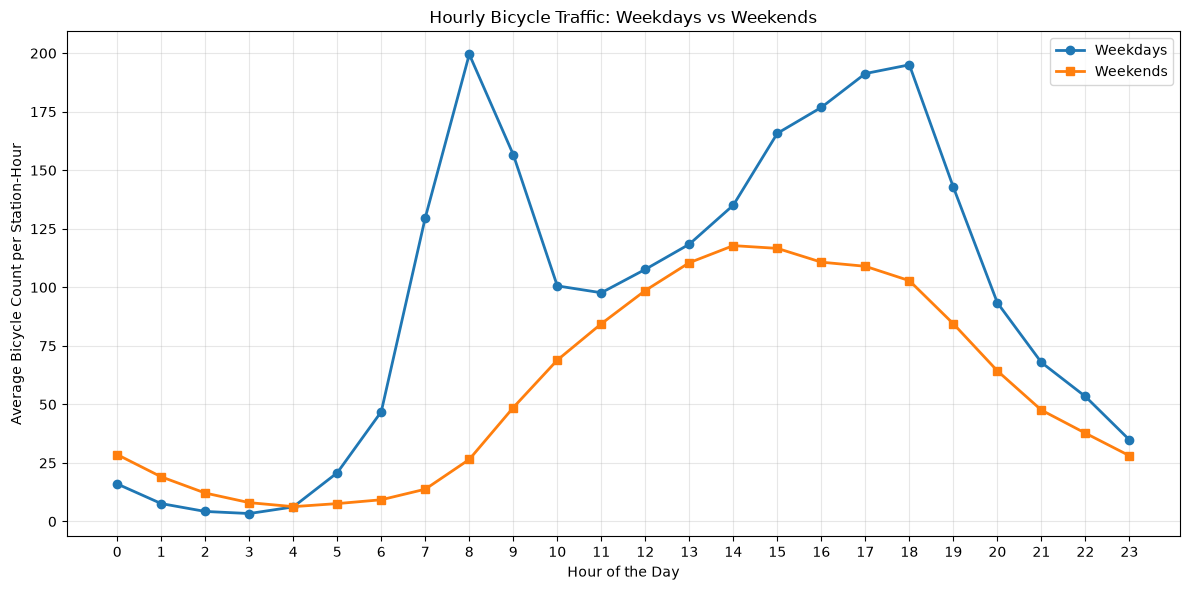

In [50]:

# Average hourly traffic split by weekday/weekend
weekday_weekend = (
    eda_stable.groupby(
        ["hour", "is_weekend"]
    )["bicycle_count"]
    .mean()
    .unstack()
    .reindex(range(24))
)

plt.figure(figsize=(12, 6))

plt.plot(
    weekday_weekend.index,
    weekday_weekend[False],
    marker="o",
    linewidth=2,
    label="Weekdays"
)

plt.plot(
    weekday_weekend.index,
    weekday_weekend[True],
    marker="s",
    linewidth=2,
    label="Weekends"
)

plt.title("Hourly Bicycle Traffic: Weekdays vs Weekends")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Bicycle Count per Station-Hour")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


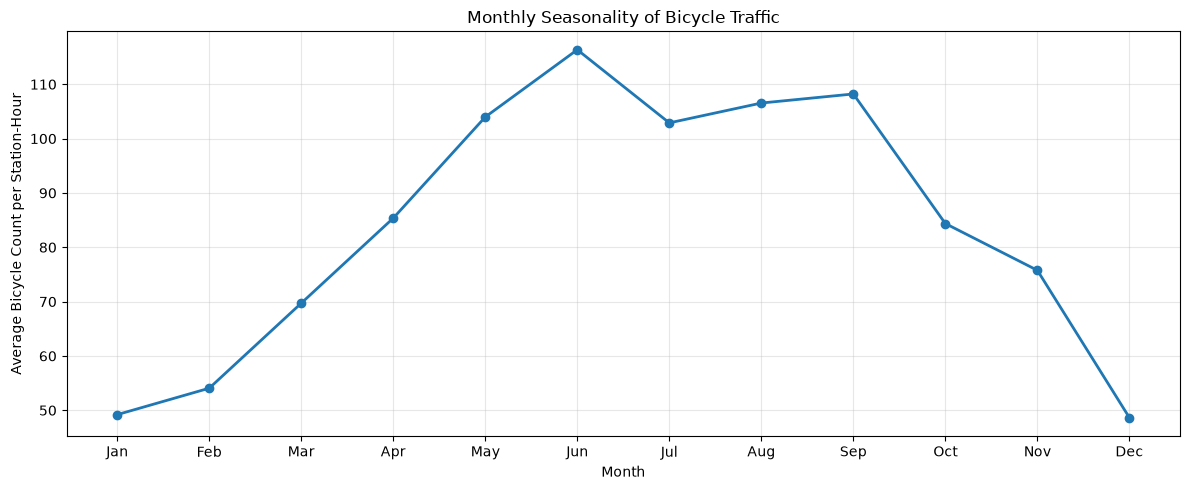

Month with highest traffic: Jun
Month with lowest traffic: Dec


In [51]:

# Average bicycle traffic by month
monthly_traffic = (
    eda_stable.groupby("month")["bicycle_count"]
    .mean()
    .reindex(range(1, 13))
)

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_traffic.index,
    monthly_traffic.values,
    marker="o",
    linewidth=2
)

plt.xticks(range(1, 13), month_names)
plt.title("Monthly Seasonality of Bicycle Traffic")
plt.xlabel("Month")
plt.ylabel("Average Bicycle Count per Station-Hour")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Month with highest traffic:",
      month_names[monthly_traffic.idxmax() - 1])

print("Month with lowest traffic:",
      month_names[monthly_traffic.idxmin() - 1])


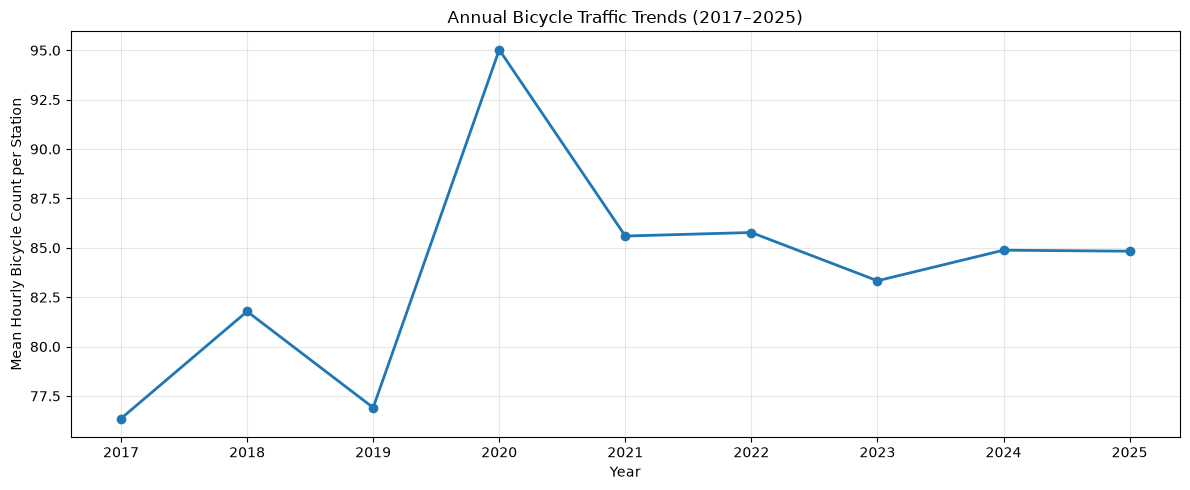

Annual traffic averages:


year
2017    76.36
2018    81.78
2019    76.91
2020    95.03
2021    85.60
2022    85.78
2023    83.33
2024    84.88
2025    84.83
Name: bicycle_count, dtype: float64


Change from 2017 to 2025: 11.09%


In [52]:

# Average hourly bicycle count for each station and year
station_year_avg = (
    eda_stable.groupby(
        ["station_id", "year"]
    )["bicycle_count"]
    .mean()
    .reset_index()
)

# Equal-weight average across stable stations
yearly_traffic = (
    station_year_avg.groupby("year")["bicycle_count"]
    .mean()
    .reindex(range(2017, 2026))
)

plt.figure(figsize=(12, 5))

plt.plot(
    yearly_traffic.index,
    yearly_traffic.values,
    marker="o",
    linewidth=2
)

plt.title("Annual Bicycle Traffic Trends (2017–2025)")
plt.xlabel("Year")
plt.ylabel("Mean Hourly Bicycle Count per Station")
plt.xticks(range(2017, 2026))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Annual traffic averages:")
display(yearly_traffic.round(2))

# Percentage change from first to last year
if yearly_traffic.loc[2017] > 0:
    change = (
        yearly_traffic.loc[2025] /
        yearly_traffic.loc[2017] - 1
    ) * 100

    print(f"\nChange from 2017 to 2025: {change:.2f}%")


In [53]:

summary = pd.DataFrame({
    "Metric": [
        "Number of stable stations",
        "Peak traffic hour",
        "Lowest traffic hour",
        "Busiest weekday",
        "Busiest month",
        "Quietest month",
        "Mean hourly traffic"
    ],
    "Value": [
        len(stable_stations),
        f"{hourly_traffic.idxmax()}:00",
        f"{hourly_traffic.idxmin()}:00",
        day_names[daily_traffic.idxmax()],
        month_names[monthly_traffic.idxmax() - 1],
        month_names[monthly_traffic.idxmin() - 1],
        round(eda_stable["bicycle_count"].mean(), 2)
    ]
})

display(summary)


,Metric,Value
0,Number of stable stations,21
1,Peak traffic hour,18:00
2,Lowest traffic hour,3:00
3,Busiest weekday,Tuesday
4,Busiest month,Jun
5,Quietest month,Dec
6,Mean hourly traffic,83.84


## 2.4.8 Key Findings

The exploratory analysis of hourly bicycle traffic from 21 consistently reporting counting stations in Berlin between 2017 and 2025 revealed several important temporal patterns.

Bicycle traffic exhibits two pronounced daily peaks, at approximately 08:00 and 18:00, suggesting substantial commuting activity. Weekday traffic is considerably higher than weekend traffic, while weekend cycling activity is concentrated more heavily during the afternoon.

Strong seasonal differences were also observed, with June exhibiting the highest average bicycle counts and December the lowest. Annual traffic levels fluctuated, with a pronounced peak in 2020 and relatively stable levels between 2021 and 2025.

These observations suggest that hour of day, day of week, weekend status, and month are promising predictors for future machine learning models.

The findings describe patterns at the selected counting stations and should not be interpreted as citywide bicycle traffic totals.

## 2.5 Advanced Visualizations

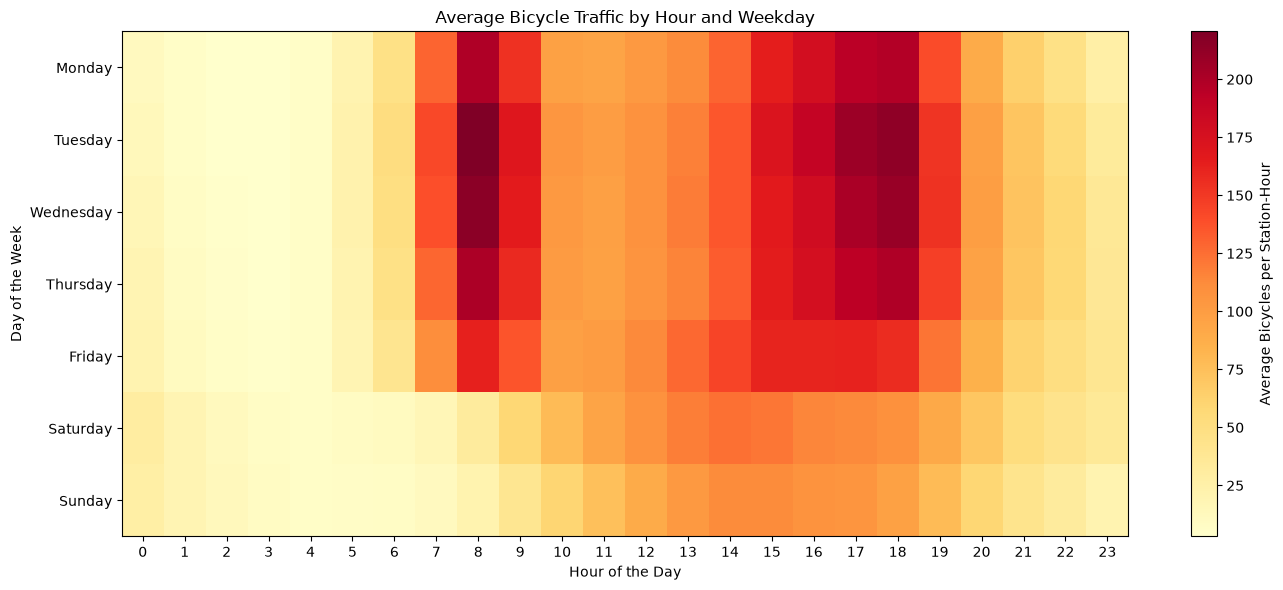

In [54]:

# Hour × Weekday Heatmap

import matplotlib.pyplot as plt

heatmap_data = (
    eda_stable.groupby(
        ["day_of_week", "hour"]
    )["bicycle_count"]
    .mean()
    .unstack()
    .reindex(index=range(7), columns=range(24))
)

fig, ax = plt.subplots(figsize=(14, 6))

im = ax.imshow(
    heatmap_data,
    aspect="auto",
    cmap="YlOrRd"
)

ax.set_xticks(range(24))
ax.set_yticks(range(7))

ax.set_yticklabels([
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
])

ax.set_xlabel("Hour of the Day")
ax.set_ylabel("Day of the Week")
ax.set_title("Average Bicycle Traffic by Hour and Weekday")

plt.colorbar(
    im,
    ax=ax,
    label="Average Bicycles per Station-Hour"
)

plt.tight_layout()
plt.show()


In [55]:

# Select recent data for station comparisons
station_df = clean_df[
    clean_df["year"].isin([2024, 2025])
].copy()

# Calculate average hourly traffic by station
station_traffic = (
    station_df.groupby("station_id")["bicycle_count"]
    .agg(
        mean_count="mean",
        median_count="median",
        max_count="max",
        observations="count"
    )
    .sort_values("mean_count", ascending=False)
)

display(station_traffic.round(2))


,mean_count,median_count,max_count,observations
station_id,,,,
05-FK-OBB-O,233.62,212.0,1066.0,17518
05-FK-OBB-W,221.66,205.0,999.0,17542
21-NK-MAY,189.26,171.0,773.0,17542
02-MI-JAN-N,142.62,116.0,884.0,17542
09-PA-SA-S,140.42,119.0,900.0,14843
07-FK-ST,135.93,95.0,886.0,14855
19-TS-MON,135.35,113.0,647.0,15315
10-PA-BER-N,127.12,100.0,585.0,17542
01-MI-AL-W,123.87,87.0,1124.0,17537


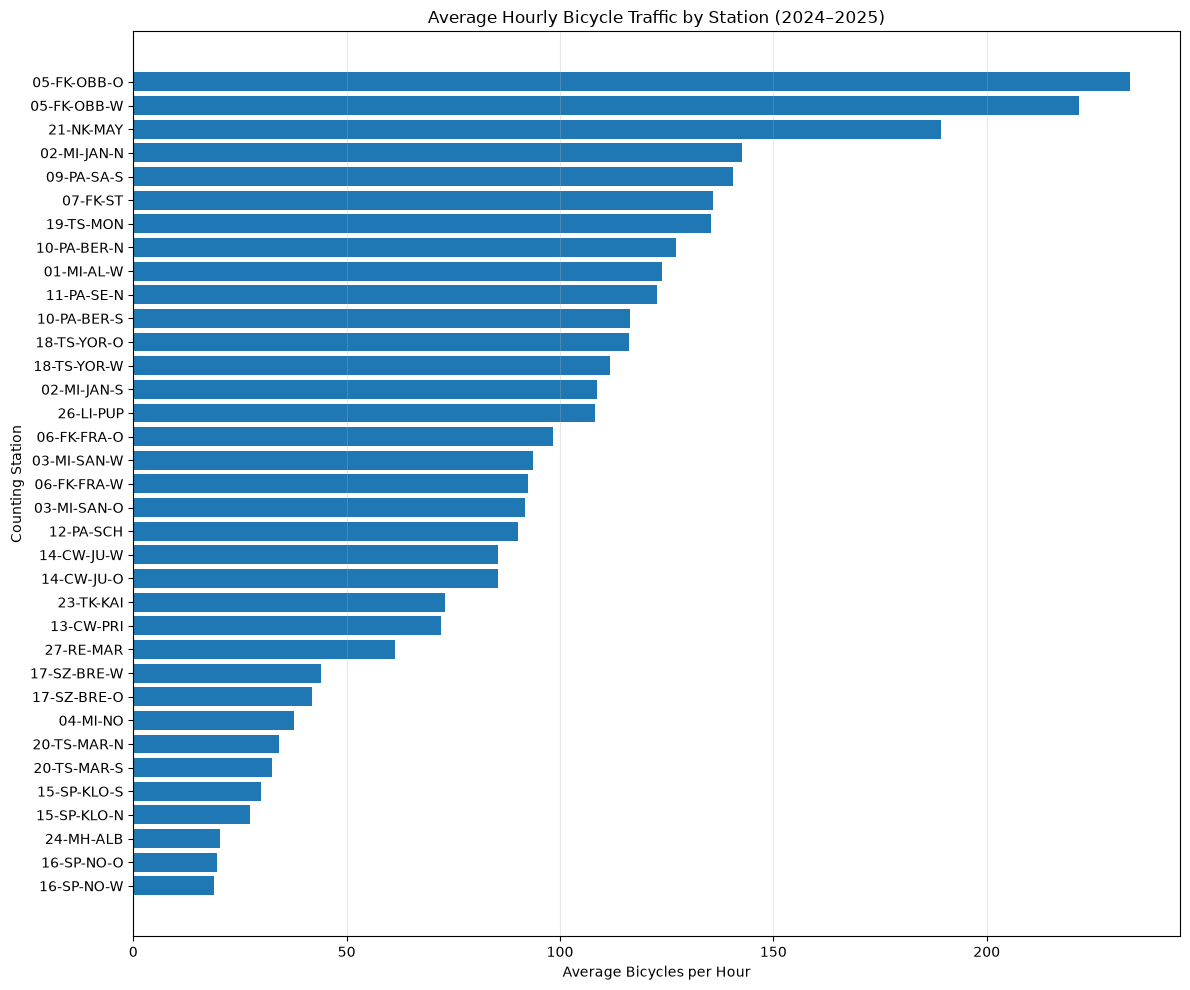

In [56]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

plt.barh(
    station_traffic.index,
    station_traffic["mean_count"]
)

plt.gca().invert_yaxis()

plt.title("Average Hourly Bicycle Traffic by Station (2024–2025)")
plt.xlabel("Average Bicycles per Hour")
plt.ylabel("Counting Station")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


## Outlier Detection and Analysis

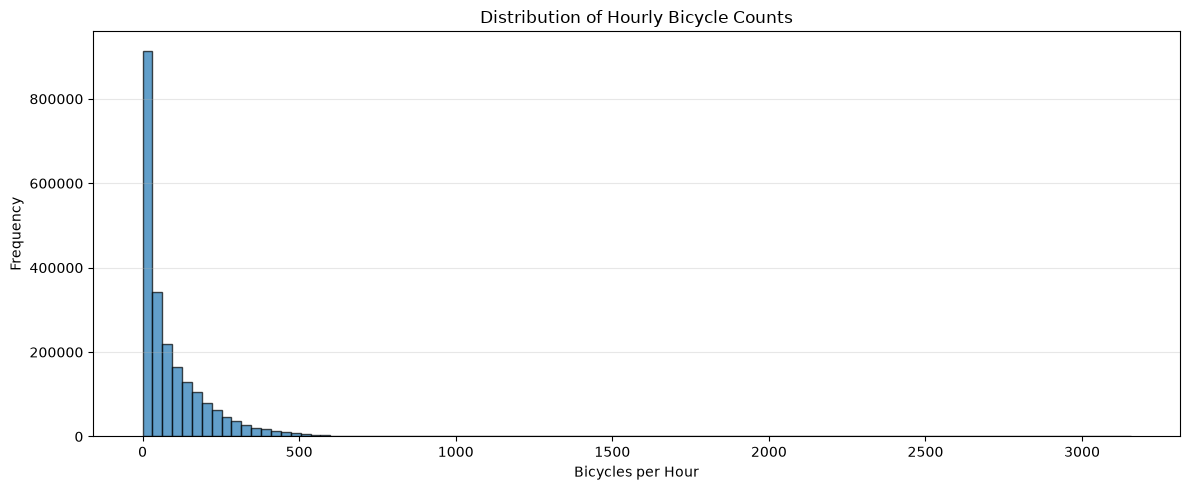

Mean: 90.92420169083434
Median: 48.0
Skewness: 2.149510969490918


In [57]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(
    clean_df["bicycle_count"],
    bins=100,
    edgecolor="black",
    alpha=0.7
)

plt.title("Distribution of Hourly Bicycle Counts")
plt.xlabel("Bicycles per Hour")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Mean:", clean_df["bicycle_count"].mean())
print("Median:", clean_df["bicycle_count"].median())
print("Skewness:", clean_df["bicycle_count"].skew())


In [58]:

# Calculate station-specific outlier thresholds
station_quartiles = (
    clean_df.groupby("station_id")["bicycle_count"]
    .quantile([0.25, 0.75])
    .unstack()
)

station_quartiles.columns = ["Q1", "Q3"]

station_quartiles["IQR"] = (
    station_quartiles["Q3"] -
    station_quartiles["Q1"]
)

station_quartiles["upper_bound"] = (
    station_quartiles["Q3"] +
    1.5 * station_quartiles["IQR"]
)

# Join thresholds with observations
outlier_df = clean_df.join(
    station_quartiles["upper_bound"],
    on="station_id"
)

# Flag potential outliers
outlier_df["is_outlier"] = (
    outlier_df["bicycle_count"] >
    outlier_df["upper_bound"]
)

print("Potential outliers:",
      outlier_df["is_outlier"].sum())

print("Percentage of observations flagged:",
      round(outlier_df["is_outlier"].mean() * 100, 2),
      "%")

# Show highest flagged counts
display(
    outlier_df[outlier_df["is_outlier"]]
    .nlargest(15, "bicycle_count")[
        ["timestamp", "station_id",
         "bicycle_count", "upper_bound"]
    ]
)


Potential outliers: 44152
Percentage of observations flagged: 1.99 %


,timestamp,station_id,bicycle_count,upper_bound
1811931,2024-10-09 10:00:00,20-TS-MAR-S,3155.0,83.5
1811932,2024-10-09 11:00:00,20-TS-MAR-S,2720.0,83.5
56355,2020-06-06 14:00:00,02-MI-JAN-N,2167.0,526.0
1639055,2022-09-26 18:00:00,19-TS-MON,2023.0,530.0
1811933,2024-10-09 12:00:00,20-TS-MAR-S,1876.0,83.5
56354,2020-06-06 13:00:00,02-MI-JAN-N,1757.0,526.0
1638983,2022-09-23 18:00:00,19-TS-MON,1677.0,530.0
135235,2020-06-06 15:00:00,02-MI-JAN-S,1592.0,518.5
1638874,2022-09-19 05:00:00,19-TS-MON,1587.0,530.0
1639570,2022-10-18 05:00:00,19-TS-MON,1585.0,530.0


,timestamp,bicycle_count
1811925,2024-10-09 04:00:00,6.0
1811926,2024-10-09 05:00:00,14.0
1811927,2024-10-09 06:00:00,29.0
1811928,2024-10-09 07:00:00,47.0
1811929,2024-10-09 08:00:00,51.0
1811930,2024-10-09 09:00:00,1452.0
1811931,2024-10-09 10:00:00,3155.0
1811932,2024-10-09 11:00:00,2720.0
1811933,2024-10-09 12:00:00,1876.0
1811934,2024-10-09 13:00:00,1528.0


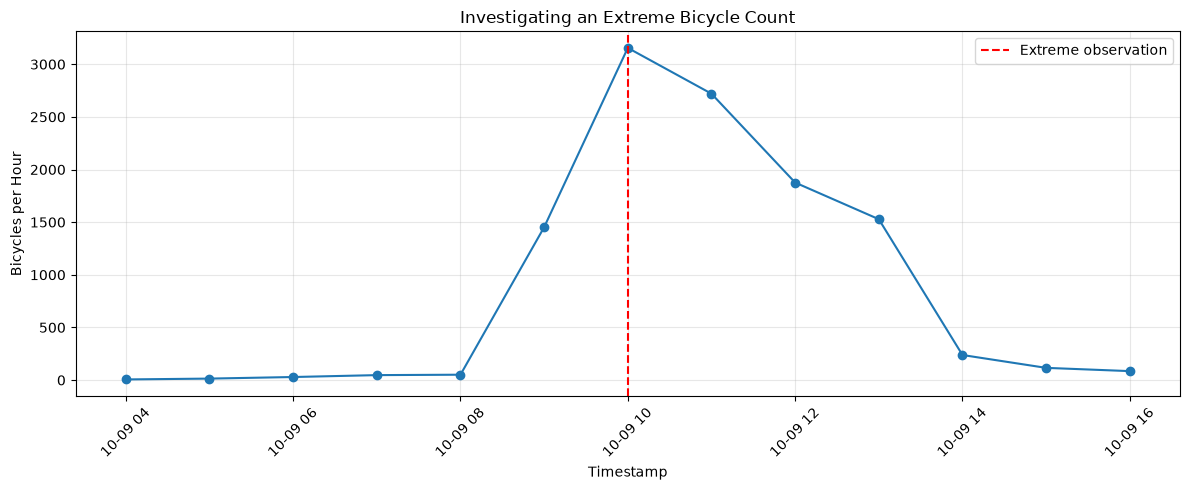

In [ ]:

#We previously identified an exceptional measurement at 20-TS-MAR-S on October 9, 2024, at 10:00.
#Let's examine the bicycle counts recorded at the same station within the surrounding six hours.

station = "20-TS-MAR-S"
event_time = pd.Timestamp("2024-10-09 10:00:00")

# Extract a six-hour window before and after
window_df = clean_df[
    (clean_df["station_id"] == station) &
    (
        clean_df["timestamp"].between(
            event_time - pd.Timedelta(hours=6),
            event_time + pd.Timedelta(hours=6)
        )
    )
].sort_values("timestamp")

display(
    window_df[["timestamp", "bicycle_count"]]
)

plt.figure(figsize=(12, 5))

plt.plot(
    window_df["timestamp"],
    window_df["bicycle_count"],
    marker="o"
)

plt.axvline(
    event_time,
    color="red",
    linestyle="--",
    label="Extreme observation"
)

plt.title("Investigating an Extreme Bicycle Count")
plt.xlabel("Timestamp")
plt.ylabel("Bicycles per Hour")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Investigation of Suspicious Traffic Events

station_id,20-TS-MAR-N,20-TS-MAR-S
timestamp,,
2024-10-09 00:00:00,0.0,3.0
2024-10-09 01:00:00,2.0,0.0
2024-10-09 02:00:00,0.0,1.0
2024-10-09 03:00:00,1.0,1.0
2024-10-09 04:00:00,7.0,6.0
2024-10-09 05:00:00,22.0,14.0
2024-10-09 06:00:00,59.0,29.0
2024-10-09 07:00:00,137.0,47.0
2024-10-09 08:00:00,111.0,51.0


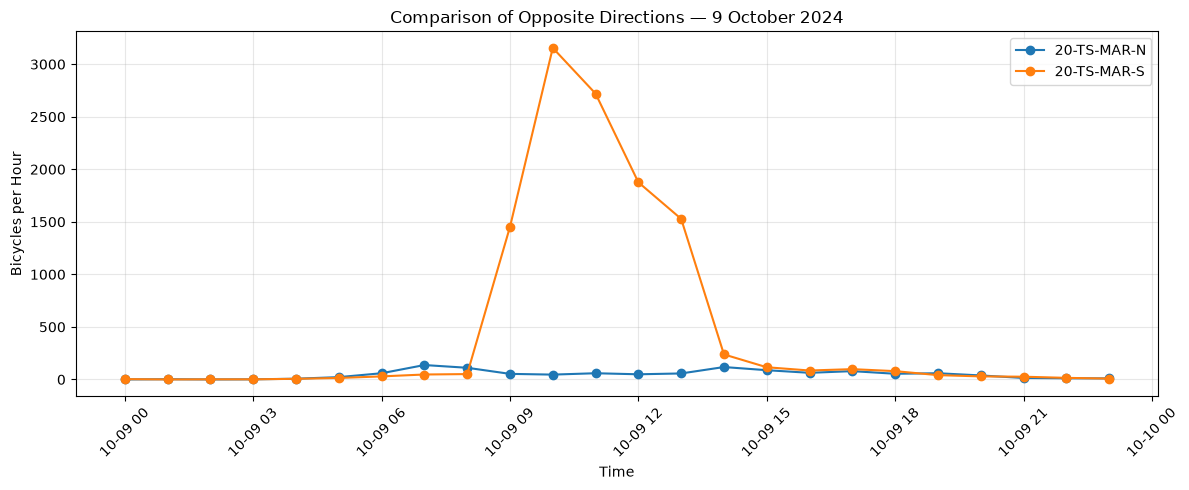

In [60]:
#Compare the extreme event with the opposite direction
#The station 20-TS-MAR-N measures the opposite direction at the same counting location.
# Comparing both directions can help us determine whether the unusually high readings were shared across both sensors.


# Compare both directions on October 9, 2024

event_day = clean_df[
    (clean_df["timestamp"].dt.date ==
     pd.Timestamp("2024-10-09").date()) &
    (clean_df["station_id"].isin([
        "20-TS-MAR-N",
        "20-TS-MAR-S"
    ]))
].copy()

comparison = event_day.pivot_table(
    index="timestamp",
    columns="station_id",
    values="bicycle_count"
)

display(comparison)

plt.figure(figsize=(12, 5))

for station in comparison.columns:
    plt.plot(
        comparison.index,
        comparison[station],
        marker="o",
        label=station
    )

plt.title("Comparison of Opposite Directions — 9 October 2024")
plt.xlabel("Time")
plt.ylabel("Bicycles per Hour")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [61]:

# Create a flagged dataset without deleting observations
quality_df = clean_df.copy()

# Calculate station-specific statistics
stats = (
    quality_df.groupby("station_id")["bicycle_count"]
    .agg(
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
)

stats["IQR"] = stats["Q3"] - stats["Q1"]

# Very extreme upper threshold
stats["extreme_threshold"] = (
    stats["Q3"] + 5 * stats["IQR"]
)

quality_df = quality_df.join(
    stats["extreme_threshold"],
    on="station_id"
)

quality_df["extreme_flag"] = (
    quality_df["bicycle_count"] >
    quality_df["extreme_threshold"]
)

print("Extremely high observations:",
      quality_df["extreme_flag"].sum())

print("Percentage flagged:",
      round(
          quality_df["extreme_flag"].mean() * 100,
          3
      ),
      "%"
)

display(
    quality_df[quality_df["extreme_flag"]]
    .groupby("station_id")
    .size()
    .sort_values(ascending=False)
    .head(15)
)


Extremely high observations: 153
Percentage flagged: 0.007 %


station_id
24-MH-ALB      56
01-MI-AL-W     52
20-TS-MAR-S    12
19-TS-MON      10
17-SZ-BRE-O     5
13-CW-PRI       4
20-TS-MAR-N     4
17-SZ-BRE-W     3
02-MI-JAN-N     2
02-MI-JAN-S     2
04-MI-NO        1
15-SP-KLO-N     1
16-SP-NO-W      1
dtype: int64

In [65]:

from pathlib import Path

output_dir = Path("C:/Users/King/OneDrive/Desktop/Berlin-Mobility-AI/data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

quality_df.to_parquet(
    output_dir / "berlin_bicycle_quality_flagged.parquet",
    index=False
)

print("Quality-flagged dataset saved successfully!")


Quality-flagged dataset saved successfully!


## Time-Series Continuity Check

In [66]:

# Check time intervals between consecutive observations

time_check = quality_df.sort_values(
    ["station_id", "timestamp"]
).copy()

time_check["time_diff"] = (
    time_check.groupby("station_id")["timestamp"]
    .diff()
)

# Count intervals longer than one hour
gaps = time_check[
    time_check["time_diff"] > pd.Timedelta(hours=1)
]

# Count duplicate or non-increasing timestamps
non_increasing = time_check[
    time_check["time_diff"] <= pd.Timedelta(0)
]

print("Intervals longer than 1 hour:", len(gaps))
print("Non-increasing timestamps:", len(non_increasing))

print("\nLargest observed gaps:")
display(
    gaps.nlargest(10, "time_diff")[
        ["station_id", "timestamp", "time_diff"]
    ]
)

print("\nStations with most gaps:")
display(
    gaps.groupby("station_id")
    .size()
    .sort_values(ascending=False)
    .head(15)
)


Intervals longer than 1 hour: 274
Non-increasing timestamps: 0

Largest observed gaps:


,station_id,timestamp,time_diff
459096,05-FK-OBB-W,2022-05-02 14:00:00,527 days 15:00:00
392901,05-FK-OBB-O,2022-05-02 14:00:00,525 days 15:00:00
1024073,14-CW-JU-O,2023-01-01 00:00:00,365 days 01:00:00
1054166,14-CW-JU-W,2023-01-01 00:00:00,365 days 01:00:00
358548,04-MI-NO,2025-12-22 11:00:00,82 days 09:00:00
1749221,20-TS-MAR-S,2017-08-14 04:00:00,20 days 05:00:00
172703,02-MI-JAN-S,2024-10-01 14:00:00,16 days 15:00:00
2108714,26-LI-PUP,2022-09-13 08:00:00,11 days 01:00:00
1905943,23-TK-KAI,2017-07-10 05:00:00,8 days 06:00:00
2108717,26-LI-PUP,2022-09-25 15:00:00,7 days 06:00:00



Stations with most gaps:


station_id
26-LI-PUP      17
10-PA-BER-S    11
06-FK-FRA-O    11
23-TK-KAI      11
02-MI-JAN-S    10
03-MI-SAN-O    10
17-SZ-BRE-W    10
19-TS-MON      10
15-SP-KLO-N    10
20-TS-MAR-S    10
13-CW-PRI       9
17-SZ-BRE-O     9
20-TS-MAR-N     9
15-SP-KLO-S     9
02-MI-JAN-N     9
dtype: int64